# Statistical Analyses

## 1. What the Metadata File Actually Contains

The metadata file describes variables from a City of Calgary citizen survey repeated across multiple years (2018–2021)

**A. Descriptive / Univariate Analysis**

    Frequency distributions for all categorical variables (e.g., income brackets, education, tenancy) — weighted using MWeight0.

    Means, medians, standard deviations for ordinal 1–10 scales (QoL, agreement items, tax value).

    Top-box percentages — the metadata explicitly provides a topbox flag (0/1), so you can compute the proportion giving favorable ratings (e.g., 7–10 on QoL, "somewhat/strongly agree" on Likert items).

    Cross-tabulations by year (qwave) to see how distributions shift over time.

**B. Bivariate Analysis**

    Chi-square tests — association between two categorical variables (e.g., income × tenancy, visible minority × quadrant).

    T-tests / ANOVA — compare mean QoL or satisfaction scores across demographic groups (e.g., age groups, income brackets).

    Correlation analysis — Spearman's rho for ordinal–ordinal relationships (e.g., QoL vs. safety, pride vs. satisfaction).

    Mann–Whitney U / Kruskal–Wallis — non-parametric alternatives for ordinal data.

**C. Longitudinal / Trend Analysis (the "2 years" angle)**

Since qwave marks the survey year, you can:

    Compare means across waves using independent-samples t-tests or ANOVA (e.g., did overall QoL change from 2018 to 2021?).

    Test for linear trends across all four waves (Jonckheere–Terpstra test for ordinal data).

    Difference-in-differences if you have a natural experiment (e.g., a policy change between waves).

    Cohort analysis — track how specific demographic subgroups' satisfaction evolved.

    Seasonal/period effects — if waves are at different times of year.

D. Multivariate Analysis

    Multiple linear regression — predict QoL or satisfaction from demographics + service ratings.

    Ordinal logistic regression (proportional odds model) — appropriate for Likert/1–10 outcomes.

    Binary logistic regression — predict top-box vs. not-top-box (using the topbox variable).

    Factor analysis / PCA — the 35 service satisfaction items (q9_1_*) and 35 importance items (q8_*) are ideal for dimension reduction to uncover latent service-quality factors.

    Cluster analysis — segment respondents by service priorities or satisfaction profiles.

    Structural Equation Modeling (SEM) — model relationships between service importance, satisfaction, and overall QoL.

    Importance–Performance Analysis (IPA) — a classic technique using q8_* (importance) and q9_1_* (satisfaction) to identify which services to prioritize. This is arguably the most natural analysis for this dataset.

E. Weighted Analysis

Because MWeight0 exists, all analyses should be weighted to be representative of the Calgary population. This affects:

    Point estimates (weighted means/proportions)

    Standard errors (design-based or bootstrap methods)

    Significance tests

F. Reliability / Psychometric Analysis

    Cronbach's alpha — internal consistency of the Likert scale batteries (e.g., q19_1–q19_8, q24bx_1–q24bx_7).

    Item-total correlations — which items best predict overall satisfaction.



### **3. Analyses Specific to the Two-Year Comparison**

If "2 different years" means you have two waves of microdata (e.g., 2018 and 2021):
Goal	Method
Did overall QoL change?	Independent t-test / Mann–Whitney on q2a
Did the demographic mix shift?	Chi-square on q30, q39, q38, etc.
Did service satisfaction change?	Paired or independent t-tests on each q9_1_*
Did importance rankings change?	Compare means/ranks on q8_*
Did the drivers of QoL change?	Compare regression coefficients across years
Did inequality in satisfaction change?	Compare variance or Gini-style dispersion measures
Did segment sizes change?	Cluster analysis per year, then compare cluster proportions
Did the importance–satisfaction gap widen?	IPA per year, then compare quadrant placements

## **Setup and Import**

In [816]:
from itertools import combinations
from os import PRIO_PGRP

import numpy as np
import seaborn as sns
import pandas as pd
from pandas.core.array_algos.replace import should_use_regex
from pandas.core.interchange import column
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from itertools import combinations
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.multitest import multipletests
import warnings
warnings.filterwarnings("ignore")




In [817]:
# Plot style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams["figure.dpi"] = 100

# Reproducibility
np.random.seed(42)

## Load the Data


In [818]:
DATA_PATH = "Citizen_Satisfaction_Survey_2016_2017.csv"

survey_2016_2017 = pd.read_csv(DATA_PATH)
print("Shape:", survey_2016_2017.shape)
print("\nColumns (first 20):", survey_2016_2017.columns[:20].tolist())

print("\nWave counts")
print(survey_2016_2017['qwave'].value_counts())


Shape: (5000, 34)

Columns (first 20): ['uid', 'Mweight0', 'qwave', 's4qt', 'market2', 'q39', 'q34', 'q37', 'q38', 'q30', 'q32x', 'q40', 'sexfix', 'q2a', 'q3', 'q24bx_1', 'q24bx_2', 'q24bx_3', 'q24bx_4', 'q24bx_5']

Wave counts
qwave
Year-2016    2500
Year-2017    2500
Name: count, dtype: int64


In [819]:
survey_2016_2017.head()


,uid,Mweight0,qwave,s4qt,market2,q39,q34,q37,q38,q30,...,q19_1,q19_2,q19_3,q19_4,q19_5,q19_6,q19_7,q19_8,q11a,q12
0,UpVkQtPG,1.16029,Year-2016,3,1,"$120,000 and over (Net)",Own,28.0,Some post secondary or college diploma,52,...,2,2,2,2,2,2,2,2,5,3
1,J18rVUv3,0.62568,Year-2016,3,1,"$105,000 to just under $120,000",Own,27.0,Completed university degree or post-grad degree,56,...,2,2,2,4,2,2,2,2,8,3
2,qTSpJwoQ,1.06411,Year-2016,3,2,"$60,000 to just under $75,000",Rent,27.0,Completed high school or less,54,...,1,1,2,1,1,1,0,1,6,3
3,r6dHCOz0,0.62568,Year-2016,3,1,"$105,000 to just under $120,000",Own,50.0,Completed university degree or post-grad degree,61,...,2,4,3,2,2,2,2,3,9,2
4,aSt5lbDH,1.96897,Year-2016,3,1,"$75,000 to just under $90,000",Rent,31.0,Some post secondary or college diploma,31,...,2,2,2,2,2,2,2,4,11,6


In [820]:
DATA_PATH_18_21 = "Citizen_Satisfaction_Survey_2018_2021.csv"
survey_2018_2021 = pd.read_csv(DATA_PATH_18_21)
print("Shape:", survey_2018_2021.shape)

print(survey_2018_2021["qwave"].value_counts())
survey_2018_2021.describe()
survey_2018_2021.isna().values.any()


Shape: (10002, 139)
qwave
Year-2019    2502
Year-2021    2500
Year-2020    2500
Year-2018    2500
Name: count, dtype: int64


np.True_

**Load the Data**

In [821]:
survey_2018_2021.tail()

,Mweight0,qwave,s4qt,market2,q39,q34,q37,q38,q30,q32x,...,q9_2_26,q9_2_27,q9_2_28,q9_2_29,q9_2_30,q9_2_31,q9_2_32,q9_2_33,q9_2_34,q9_2_35
9997,1.03,Year-2018,2,9,1,2,2,2,3,1,...,1,3,3,1,1,1,3,1,3,3
9998,0.93,Year-2018,4,5,7,1,8,3,3,2,...,2,2,1,1,2,1,1,2,2,2
9999,0.69,Year-2018,3,1,6,1,11,3,5,2,...,1,1,1,3,3,1,3,1,3,1
10000,1.15,Year-2018,1,6,8,1,11,2,4,2,...,2,2,3,3,3,3,3,3,3,3
10001,0.50,Year-2018,1,10,8,1,11,3,6,2,...,2,3,3,3,3,3,3,3,3,1


**Get only want 2020 and 2021**

In [822]:
survey_20_21_df = survey_2018_2021[survey_2018_2021["qwave"].isin(["Year-2020", "Year-2021"])].copy()
print(survey_20_21_df["qwave"].value_counts())
print("Filtered shape: ", survey_20_21_df.shape)

qwave
Year-2021    2500
Year-2020    2500
Name: count, dtype: int64
Filtered shape:  (5000, 139)


**Define Variable Groups**



**Define Variable Groups**

In [823]:
# Ordinal 1-10 items
ordinal_1_10 = ["q2a", "q11a"] + [f"q24bx_{i}" for i in range(1, 8)]

# Ordinal 1-4 items (Likert / satisfaction / importance)
ordinal_1_4_likert = [f"q19_{i}" for i in range(1, 9)] + ["q24cx"]
ordinal_1_4_other = ["q10"]
service_importance = [f"q8_{i}" for i in range(1, 36)]
service_satisfaction = [f"q9_1_{i}" for i in range(1, 36)]
service_investment = [f"q9_2_{i}" for i in range(1, 36)]

# Categorical
categorical_items = ["q3", "q12"]

# Demographics
demographics = ["s4qt", "market2", "q39", "q34", "q37", "q38", "q30", "q32x", "q40", "q29x"]

# Weight
WEIGHT = "Mweight0"



**Clean Missing / Non-Response Codes**


Based on the metadata, ordinal scales often use codes like 9, 10, 11, 12 for "Don't know" / "Prefer not to answer." These must be converted to NaN before analysis.

In [824]:
def clean_ordinal(df, cols, valid_max):
    """
    Replace out-of-range codes with NaN.
    valid_max = highest valid substantive code (e.g., 10 for 1-10 scales).
    """
    df = df.copy()
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
            df.loc[~df[c].between(1, valid_max), c] = np.nan
    return df

# 1-10 scales: valid 1-10
survey_20_21_df = clean_ordinal(survey_20_21_df, ordinal_1_10, 10)

# 1-4 Likert / satisfaction / importance: valid 1-4
survey_20_21_df = clean_ordinal(survey_20_21_df, ordinal_1_4_likert + ordinal_1_4_other +
                       service_importance + service_satisfaction, 4)

# 1-5 investment: valid 1-5
survey_20_21_df = clean_ordinal(survey_20_21_df, service_investment, 5)

# Categorical: keep as-is but check
for c in categorical_items + demographics:
    if c in survey_20_21_df.columns:
        survey_20_21_df[c] = pd.to_numeric(survey_20_21_df[c], errors="coerce")

print("Cleaning complete.")

Cleaning complete.


Weighted Descriptive Statistics by Year

In [825]:
def weighted_mean(df, var, weight=WEIGHT):
    """Weighted mean ignoring NaN."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return np.nan
    return np.average(d[var], weights=d[weight])

def weighted_prop_topbox(df, var, topbox_values, weight=WEIGHT):
    """Weighted proportion of respondents in topbox_values."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return np.nan
    mask = d[var].isin(topbox_values)
    return np.average(mask, weights=d[weight])

def weighted_freq(df, var, weight=WEIGHT):
    """Weighted frequency table."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return pd.Series(dtype=float)
    return d.groupby(var)[weight].sum() / d[weight].sum()

In [826]:
def weighted_mean(df, var, weight=WEIGHT):
    """Weighted mean ignoring NaN."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return np.nan
    return np.average(d[var], weights=d[weight])

def weighted_prop_topbox(df, var, topbox_values, weight=WEIGHT):
    """Weighted proportion of respondents in topbox_values."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return np.nan
    mask = d[var].isin(topbox_values)
    return np.average(mask, weights=d[weight])

def weighted_freq(df, var, weight=WEIGHT):
    """Weighted frequency table."""
    d = df[[var, weight]].dropna()
    if d.empty:
        return pd.Series(dtype=float)
    return d.groupby(var)[weight].sum() / d[weight].sum()

Headline Indicators

In [827]:
qol_df= survey_20_21_df[['Mweight0', 'qwave', 's4qt', 'q39', 'q37', 'q38', 'q30', 'sexfix', 'q29x', 'q2a', 'q3', 'q10']]
print(qol_df)

      Mweight0      qwave  s4qt  q39  q37  q38  q30  sexfix  q29x  q2a  q3  \
0         0.51  Year-2021     4    4    9    3    6       2   1.0  6.0   2   
1         0.60  Year-2021     1    1    9    2    6       1   2.0  6.0   2   
2         0.70  Year-2021     2    7    8    2    6       2   1.0  8.0   3   
3         0.49  Year-2021     3    9    8    3    6       2   1.0  7.0   3   
4         0.77  Year-2021     1    4   10    2    5       2   1.0  8.0   1   
...        ...        ...   ...  ...  ...  ...  ...     ...   ...  ...  ..   
4995      1.03  Year-2020     1    9   11    3    7       1   2.0  6.0   3   
4996      0.72  Year-2020     4    3   11    2    6       1   2.0  7.0   3   
4997      0.92  Year-2020     4    6    3    2    3       2   1.0  7.0   2   
4998      0.54  Year-2020     3    1    8    2    5       2   1.0  5.0   3   
4999      1.05  Year-2020     3    8   11    2    4       1   2.0  6.0   3   

      q10  
0     2.0  
1     2.0  
2     4.0  
3     1.0  
4  

Headline Indicators

In [828]:
qol_df = qol_df.rename(columns={"qwave": 'Year_of_survey', "s4qt":'Quadrant', 'q39': 'Household_income', 'q37': 'Years_in_Calgary', 'q38': 'Highest_education_level', 'q30': 'Age_group', 'sexfix': 'Gender_assumed', 'q29x': 'Gender', 'q2a': 'Overall_QOL', 'q3': 'Change_in_QOL', 'q10': 'Safety'})
qol_df

,Mweight0,Year_of_survey,Quadrant,Household_income,Years_in_Calgary,Highest_education_level,Age_group,Gender_assumed,Gender,Overall_QOL,Change_in_QOL,Safety
0,0.51,Year-2021,4,4,9,3,6,2,1.0,6.0,2,2.0
1,0.60,Year-2021,1,1,9,2,6,1,2.0,6.0,2,2.0
2,0.70,Year-2021,2,7,8,2,6,2,1.0,8.0,3,4.0
3,0.49,Year-2021,3,9,8,3,6,2,1.0,7.0,3,1.0
4,0.77,Year-2021,1,4,10,2,5,2,1.0,8.0,1,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,1.03,Year-2020,1,9,11,3,7,1,2.0,6.0,3,3.0
4996,0.72,Year-2020,4,3,11,2,6,1,2.0,7.0,3,3.0
4997,0.92,Year-2020,4,6,3,2,3,2,1.0,7.0,2,3.0
4998,0.54,Year-2020,3,1,8,2,5,2,1.0,5.0,3,1.0


In [829]:
# Create a reusable function to convert
def apply_label(df, col, mapping, ordered_categories=None) :
    df = df.copy()
    df[col] = pd.to_numeric(df[col], errors="coerce")
    labels = df[col].map(mapping)

    if ordered_categories is not None:
        labels = pd.Categorical(labels, categories=ordered_categories, ordered=True)

    df[col + "_label"] = labels
    return df


In [830]:
qol_with_label_df = qol_df.copy()


In [831]:
quadrant_map = {1: "SW", 2: "SE", 3: "NW", 4: "NE"}
qol_with_label_df["Quadrant"] = qol_df["Quadrant"].map(quadrant_map)


In [832]:
gender_map = {1: 'Male', 2: 'Female'}
qol_with_label_df["Gender"] = qol_df["Gender"].map(gender_map)

In [833]:
income_map = {1: "<30", 2: "30_to_45", 3: "45_to_60", 4: "60_to_75", 5: "75_to_90", 6: "90_to_105", 7: "105_to_120", 8: ">=120" }
qol_with_label_df["Household_income"] = qol_df["Household_income"].map(income_map)


In [834]:
education_level_map = {1: "HighSchoolOrLess", 2: "SomePostSecondary", 3: "CompleteUniversity"}
qol_with_label_df["Highest_education_level"] = qol_df["Highest_education_level"].map(education_level_map)


In [835]:
change_in_qol_map = {1: "Improved", 2: "Same", 3: "Worsened"}
qol_with_label_df["Change_in_QOL"] = qol_df["Change_in_QOL"].map(change_in_qol_map)


In [836]:
safety_map = {1: "Very Unsafe", 2: "Somewhat Unsafe", 3: "Reasonably Safe", 4: 'Very Safe'}
qol_with_label_df["Safety"] = qol_df["Safety"].map(safety_map)

In [837]:
def qol_action_oriented_split(score):
    if score < 5:
        return "Poor"
    if score < 7:
        return "Fair"
    if score < 9:
        return "Good"
    if score <= 10:
        return "Very_Good"
    return np.nan


qol_with_label_df["Overall_QOL"] = qol_df["Overall_QOL"].map(qol_action_oriented_split)

In [838]:
print(qol_with_label_df.isna().sum())
print(qol_with_label_df.describe())
print(qol_with_label_df.head())


Mweight0                      0
Year_of_survey                0
Quadrant                      0
Household_income           1175
Years_in_Calgary              0
Highest_education_level     104
Age_group                     0
Gender_assumed                0
Gender                       33
Overall_QOL                   7
Change_in_QOL                46
Safety                       11
dtype: int64
          Mweight0  Years_in_Calgary    Age_group  Gender_assumed
count  5000.000000       5000.000000  5000.000000     5000.000000
mean      1.000158          6.736000     4.324400        1.518200
std       0.532800          3.157705     1.597772        0.499719
min       0.290000          1.000000     1.000000        1.000000
25%       0.600000          4.000000     3.000000        1.000000
50%       0.870000          7.000000     5.000000        2.000000
75%       1.160000         10.000000     6.000000        2.000000
max       5.120000         12.000000     7.000000        2.000000
   Mweigh

## Compare 2020 vs. 2021 — Grouped Bar Chart



In [839]:


plot_df = qol_with_label_df[['Year_of_survey', 'Household_income', 'Mweight0']].dropna()

# Weighted % within each wave
plot_df = plot_df.groupby(['Year_of_survey', 'Household_income'])['Mweight0'].sum().reset_index()
plot_df['pct'] = plot_df.groupby('Year_of_survey')['Mweight0'].transform(lambda x: x/x.sum() * 100)

plot_df


,Year_of_survey,Household_income,Mweight0,pct
0,Year-2020,105_to_120,234.38,10.567797
1,Year-2020,30_to_45,185.07,8.344493
2,Year-2020,45_to_60,213.85,9.642134
3,Year-2020,60_to_75,201.94,9.105132
4,Year-2020,75_to_90,193.06,8.704748
5,Year-2020,90_to_105,253.66,11.437100
6,Year-2020,<30,145.27,6.549978
7,Year-2020,>=120,790.64,35.648618
8,Year-2021,105_to_120,221.22,13.398341
9,Year-2021,30_to_45,168.06,10.178669


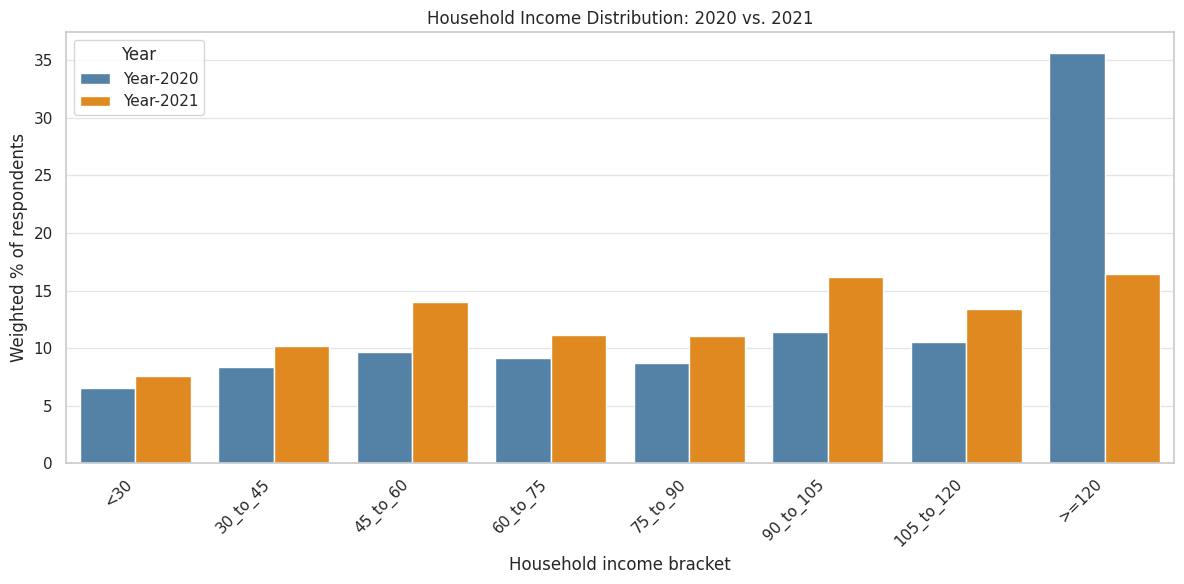

In [840]:
plot_df["Household_income"] = pd.Categorical(plot_df["Household_income"], categories=income_map.values(), ordered=True)

ax = sns.barplot(

    data=plot_df,
    x='Household_income',
    y= "pct",
    hue= "Year_of_survey",
    palette=['steelblue', 'darkorange']
)
ax.set_ylabel("Weighted % of respondents")
ax.set_xlabel("Household income bracket")
ax.set_title("Household Income Distribution: 2020 vs. 2021")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

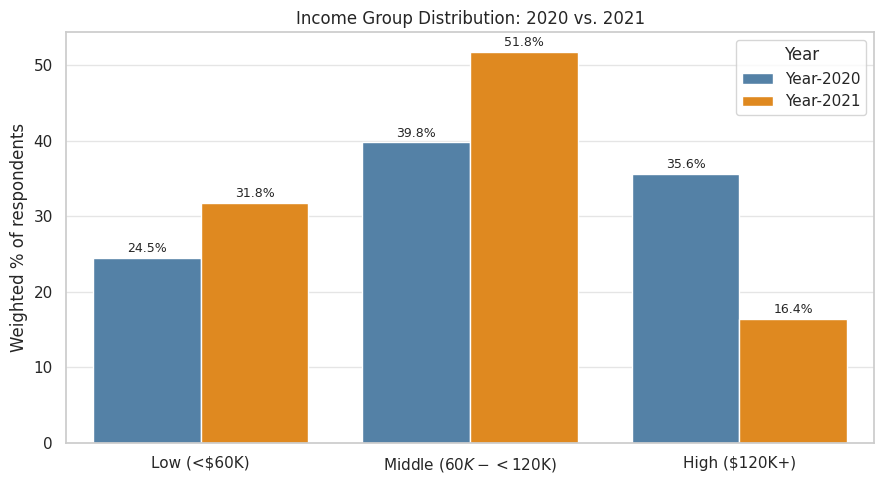

In [841]:
def income_group(code):
    if code in ["<30", "30_to_45", "45_to_60"]:
        return "Low (<$60K)"
    if code in ["60_to_75", "75_to_90", "90_to_105", "105_to_120"]:
        return "Middle ($60K-<$120K)"
    if code in [">=120"]:
        return "High ($120K+)"
    return np.nan

qol_with_label_df["Income_group"] = qol_with_label_df["Household_income"].apply(income_group)
# print(qol_with_label_df["Income_group"].dropna())
Income_group_order = ["Low (<$60K)", "Middle ($60K-<$120K)", "High ($120K+)"]

plot2_df = qol_with_label_df[['Year_of_survey', 'Income_group', 'Mweight0']].dropna()
plot2_df["Income_group"] = pd.Categorical(plot2_df["Income_group"], categories=Income_group_order, ordered=True)


# Weighted % within each wave
plot2_df = plot2_df.groupby(['Income_group', 'Year_of_survey'])['Mweight0'].sum().reset_index()
plot2_df['pct'] = plot2_df.groupby('Year_of_survey')['Mweight0'].transform(lambda x: x/x.sum() * 100)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot2_df,
    x="Income_group",
    y="pct",
    hue="Year_of_survey",
    palette=['steelblue', 'darkorange'],
)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
ax.set_ylabel("Weighted % of respondents")
ax.set_xlabel("")
ax.set_title("Income Group Distribution: 2020 vs. 2021")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig("income_grouped.png", dpi=150)
plt.show()




## **Plot the income by quadrant**


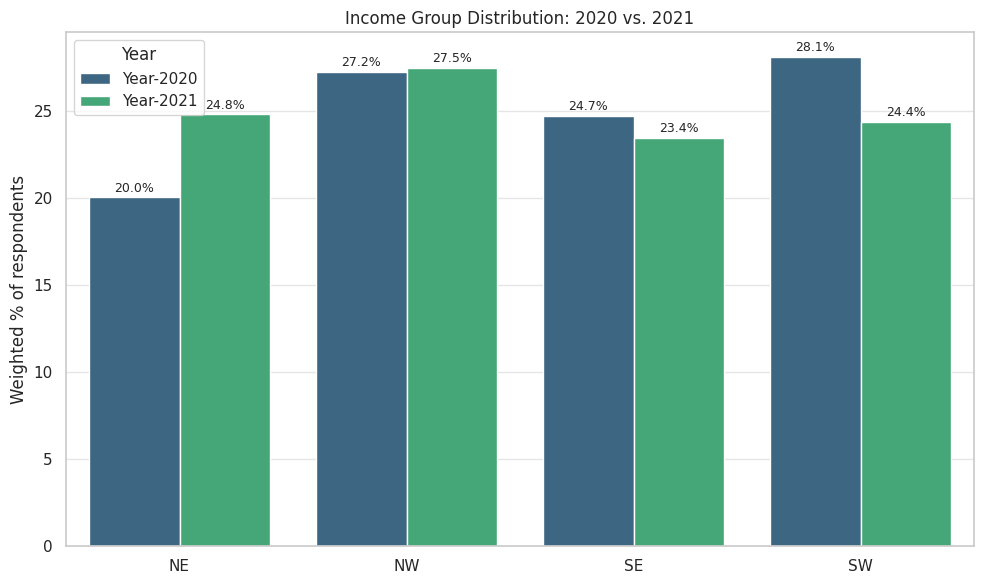

In [842]:
plot3_df = qol_with_label_df[['Year_of_survey', 'Household_income', 'Quadrant', 'Mweight0']].dropna()

def wmean(x, w):
    return (x * w).sum() / w.sum()


# Weighted % within each wave
#plot2_df = plot2_df.groupby(['Income_group', 'Year_of_survey'])['Mweight0'].sum().reset_index()
#plot2_df['pct'] = plot2_df.groupby('Year_of_survey')['Mweight0'].transform(lambda x: x/x.sum() * 100)
plot3_df = (plot3_df.groupby(['Year_of_survey', 'Quadrant']).sum().reset_index())
plot3_df['mean_income'] = plot3_df.groupby(['Year_of_survey'])['Mweight0'].transform((lambda x: x/x.sum() * 100))


plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=plot3_df,
    x="Quadrant",
    y="mean_income",
    hue="Year_of_survey",
    palette='viridis',
)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
ax.set_ylabel("Weighted % of respondents")
ax.set_xlabel("")
ax.set_title("Income Group Distribution: 2020 vs. 2021")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig("income_grouped.png", dpi=150)
plt.show()


## Dataset at a glance
Feature	What it gives you
|Column 1                           | Column  2                                             |
| :----------                      | :---------------                                            |
| Mweight0	                        | Survey weights → all estimates should be weighted            |
|qwave (2018–2021)                  |	Repeated cross-section → trend analysis                   |
| s4qt, market2, sexfix, q2a, q3	| Grouping / demographic variables            |
| q39, q34, q37, q38, q30, q32x, q40| Ordinal scales (satisfaction, trust, etc.) |
| q8_*, q9_1_*, q9_2_*, q24bx_*, q19_* |	Battery items (Likert / multi-select) |
| q10, q11a, q12, q29x, q24cx |	Categorical / behavioral |

## 2. Group comparisons (hypothesis testing)

| Test	                   | When to use	        | Example                       |
|:-----------------------|:-------------------|:------------------------------|
| Weighted t-test	        | 2 groups, numeric	  | Income code by sex            |
| Weighted chi-square    | 	2 categorical vars	 | Income × quadrant             |
| ANOVA / Kruskal-Wallis | 	3+ groups, ordinal	 | Satisfaction across quadrants |
| Mann-Whitney U	         | 2 groups, ordinal  | 	Satisfaction: male vs female  |
| Proportion z-test      | 	2  proportions	     | % satisfied in Q1 vs Q4       |

## 1. Descriptive / weighted summaries

* **Weighted means, medians, modes** per group (groupby + custom weighted mean)
* **Weighted frequency tables** for categorical vars (q39, q10, q12)
* **Cross-tabs** with pd.crosstab(..., values='Mweight0', aggfunc='sum')
* **Proportions with 95% CIs** (survey-adjusted)
* **Missingness patterns** — note your data has many blank q19_* fields


## 2. Group comparisons (hypothesis testing)
| Test	                   | When to use        | 	Example                       |
|:-----------------------|:-------------------|:------------------------------|
| Weighted t-test	        | 2 groups, numeric	  | Income code by sex            |
| Weighted chi-square	    | 2 categorical vars	 | Income × quadrant             |
| ANOVA / Kruskal-Wallis | 	3+ groups, ordinal	 | Satisfaction across quadrants |
| Mann-Whitney U	         | 2 groups, ordinal  | 	Satisfaction: male vs female  |
| Proportion z-test	      | 2 proportions	      | % satisfied in Q1 vs Q4       |

Always apply weights. For survey data use statsmodels' DescrStatsW or the survey package in R.

## 3. Ordinal analysis (your q8_*, q9_*, q39 scales)

Since these are Likert-type:

* Ordinal logistic regression (mord.Logit in statsmodels) — e.g. satisfaction ~ quadrant + year + sex
* Cumulative link models (R: ordinal::clm)
* Spearman / Kendall tau correlations between ordinal items
* Wilcoxon signed-rank for paired items (e.g. q9_1_x vs q9_2_x)

## 4. Reliability & scale construction

For the batteries (q8_1…q8_35, q9_1_*, q9_2_*):

* Cronbach's alpha — internal consistency
* McDonald's omega — better alpha alternative
* Exploratory Factor Analysis (EFA) — find latent dimensions
* Confirmatory Factor Analysis (CFA) — test structure (R: lavaan)
* Item-total correlations — drop weak items
* PCA — reduce 35 items to a few components

## 5. Dimensionality reduction & clustering

    PCA / Factor Analysis on Likert batteries

    K-means / hierarchical clustering on respondent profiles

    Latent Class Analysis (LCA) — find unobserved respondent types

    Correspondence Analysis — for categorical × categorical tables

    UMAP / t-SNE for visualization

## 6. Regression modeling

| Model	                                                       | Target	                         | Predictors                  |
|:------------------------------------------------------------|:-------------------------------|:----------------------------|
| OLS (weighted)	Satisfaction score	Quadrant, year, sex, market |
| Logistic                                                    | 	Binary outcome (satisfied y/n)	 | Demographics                |
| Ordinal logistic                                            | 	Likert satisfaction            | 	Quadrant + controls         |
| Multinomial logistic                                        | 	Income category                | 	Quadrant, market, sex       |
| Poisson / NegBin	                                            | Count outcomes	                 | Any                         |
| Mixed-effects                                               | 	Repeated year	                  | Random intercept per market |

## 7. Time / trend analysis (you have 2018–2021)

* Year-over-year change in weighted means with CIs
* Interrupted time series — did COVID (2020) shift satisfaction?
* Joinpoint regression — detect trend breaks
* Difference-in-differences — quadrant × year interactions
* Seasonal decomposition (if wave timing allows)
* Cochran-Armitage trend test — ordinal trend across years



## 8. Mediation & moderation

    Mediation: quadrant → trust (q8_*) → satisfaction (q39)

    Moderation: does sex moderate quadrant → satisfaction?

    Use pingouin (Python) or lavaan / processR (R)

## 9. Multivariate techniques

    MANOVA — multiple ordinal DVs across quadrants

    Canonical correlation — two sets of survey items

    SEM (Structural Equation Modeling) — full path models

    Partial Least Squares (PLS-SEM) — good for small samples

## 10. Survey-specific methods (important given Mweight0)

    Design-based inference — account for weights, strata, clusters

    Raking / post-stratification checks

    Design effect (DEFF) — how much weights inflate variance

    Weighted bootstrap for CIs

    R package survey — gold standard:

## 11. Spatial / market analysis

Using market2 (10–14 markets):

    Market-level weighted means with CIs

    Small-area estimation for markets with low N

    Multilevel model: respondents within markets

    Ranking with uncertainty (not just point estimates)

## Suggested starter pipeline

    Clean: encode ordinal vars, handle q19_* missingness, confirm maps

    Describe: weighted frequency + mean tables by year, quadrant, market

    Reliability: Cronbach's α on q8_* and q9_1_* batteries

    Compare: weighted ANOVA of q39 across quadrants × years

    Model: ordinal logistic — q39 ~ quadrant + year + sex + market (weighted)

    Factor: EFA on q9_1_* to build a satisfaction index

    Trend: plot weighted mean index over 2018–2021, by quadrant



Recommended tooling

| Task	               | Python	                               | R             |
|:-------------------|:-------------------------------------|:--------------|
| Weighted stats     | 	statsmodels (DescrStatsW, WLS)	       | survey        |
| Ordinal regression	 | statsmodels.miscmodels.ordinal_model | 	ordinal::clm  |
| Factor / SEM	       | factor_analyzer, semopy	              | lavaan, psych |
| Reliability	        | pingouin.cronbach_alpha              | 	psych::alpha  |
| Mediation	          | pingouin.mediation_analysis	          | mediation     |
| Clustering	         | sklearn, yellowbrick	                 | mclust        |

# Two Proportions Z-test for % satisfied in NE and SW, using the survey wight



In [843]:
#print(qol_with_label_df)
# qol_with_label_df = qol_with_label_df[qol_with_label_df["Year_of_survey"] == "Year-2021"]
# print(qol_with_label_df.head())
# print(qol_with_label_df.tail())
print(qol_with_label_df.shape)

(5000, 13)


In [844]:
qol_with_label_df["Satisfied"] = ((qol_with_label_df["Household_income"] == "90_to_105") | (qol_with_label_df["Household_income"] == "105_to_120")).astype(int)
#print(qol_with_label_df["Satisfied"].tolist())

qol_with_label_df["Weight"] = pd.to_numeric(qol_with_label_df['Mweight0'], errors='coerce')

# Keep rows with essentials
d = qol_with_label_df.dropna(subset=['Quadrant', 'Satisfied', 'Weight']).copy()

# Optional: Restrict to a year
d = d[d['Year_of_survey'] == "Year-2021"]


In [845]:
## Two-proportion z-test (weighted) Year 2021
def wprop(group):
    n_w = group['Weight'].sum()  # Weight total
    k_w = (group['Satisfied'] * group['Mweight0']).sum() # Weight success
    return pd.Series({'n_w': n_w, 'k_w': k_w, 'p_hat': k_w / n_w})

# summary = d[d["Quadrant"].isin(['NE', 'NW', 'SE', 'SW'])].groupby('Quadrant').apply(wprop)
summary = d[d["Quadrant"].isin(['NE', 'SW'])].groupby('Quadrant').apply(wprop)
#summary = d.groupby('Quadrant').apply(wprop)
summary


,n_w,k_w,p_hat
Quadrant,,,
NE,499.66,121.42,0.243005
SW,700.45,118.55,0.169248


### Two proportions Z-Test (Year 2021)

**H₀:** proportion satisfied in NE (2021) = proportion satisfied in SW (2021)

**H₁:** proportion satisfied in NE (2021) $\ne$ proportion satisfied in SW (2021)

In [846]:
counts = summary['k_w'].values         # weighted successes
print(counts)
nobs   = summary['n_w'].values         # weighted totals

zstat, p_val = proportions_ztest(count=counts, nobs=nobs, alternative='two-sided')

print(f"z = {zstat:.3f}, p = {p_val:.4g}")

[121.42 118.55]
z = 3.149, p = 0.001637


### Confidence interval for the difference

In [847]:
# With 95%  Confidence Level
p1, p4 = summary['p_hat'].values
n1, n4 = summary['n_w'].values

se_diff = np.sqrt(p1*(1-p1)/n1 + p4*(1-p4)/n4)
diff    = p4 - p1
ci_low, ci_high = diff - 1.96*se_diff, diff + 1.96*se_diff

print(f"p(Q4) - p(Q1) = {diff:+.3f}  (95% CI: {ci_low:+.3f} to {ci_high:+.3f})")

p(Q4) - p(Q1) = -0.074  (95% CI: -0.121 to -0.027)


all-pairs two-proportion z-test with Bonferroni correction for satisfaction across quadrants


In [848]:

def all_pairs_props(d, group_col, success_col='Satisfied', weight_col='Weight',
                    alternative='two-sided', method='bonferroni', alpha=0.05):
    # Weighted proportion per group
    agg = d.groupby(group_col).apply(
        lambda g: pd.Series({
            'n_w': g[weight_col].sum(),
            'k_w': (g[success_col] * g[weight_col]).sum()
        })
    )
    agg['p_hat'] = agg['k_w'] / agg['n_w']

    groups = sorted(agg.index)
    pairs = list(combinations(groups, 2))
    m = len(pairs)    # number of comparisons

    # Bonferroni-adjusted alpha
    alpha_adj = alpha / m

    rows = []
    for g1, g2 in pairs:
        p1, n1 = agg.loc[g1, ['p_hat','n_w']]
        p2, n2 = agg.loc[g2, ['p_hat','n_w']]

        z, p = proportions_ztest(
            count=[agg.loc[g1,'k_w'], agg.loc[g2,'k_w']],
            nobs =[n1, n2],
            alternative=alternative
        )

        # SE & CI for the difference
        se   = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
        diff = p2 - p1
        # Adjust CI width for Bonferroni (z_{alpha/2m})
        from scipy.stats import norm
        z_crit = norm.ppf(1 - alpha_adj/2)
        ci_lo, ci_hi = diff - z_crit*se, diff + z_crit*se

        rows.append({
            'group_1': g1,
            'group_2': g2,
            'p_1': p1,
            'p_2': p2,
            'diff': diff,
            'se': se,
            'ci_low': ci_lo,
            'ci_high': ci_hi,
            'z': z,
            'p_raw': p,
            'p_bonf': min(p * m, 1.0),
            'sig_bonf': min(p * m, 1.0) < alpha,
        })

    res = pd.DataFrame(rows)
    res['alpha_adj'] = alpha_adj
    return res, agg, m





In [849]:
def print_pairs(res, agg, m, alpha=0.05):
    print(f"Comparisons: {m}   Bonferroni α = {alpha/m:.4f}\n")
    print("Group proportions:")
    print(agg[['n_w','k_w','p_hat']].round(3))
    print()

    header = f"{'G1':<5} {'G2':<5}  {'p(G1)':>7}  {'p(G2)':>7}  {'diff':>8}  {'CI':>20}  {'p_raw':>9}  {'p_bonf':>9}  sig"
    print(header)
    print("-" * len(header))

    for _, r in res.iterrows():
        diff_s = f"{r['diff']:+.1%}"          # sign baked in as string
        ci_s   = f"[{r['ci_low']:+.1%}, {r['ci_high']:+.1%}]"
        sig    = "✓" if r['sig_bonf'] else ""

        print(
            f"{r['group_1']:<5} {r['group_2']:<5}"
            f"  {r['p_1']:>7.1%}"
            f"  {r['p_2']:>7.1%}"
            f"  {diff_s:>8}"
            f"  {ci_s:>20}"
            f"  {r['p_raw']:>9.3g}"
            f"  {r['p_bonf']:>9.3g}"
            f"  {sig}"
        )

In [850]:
res, agg, m = all_pairs_props(d, group_col='Quadrant')
print_pairs(res, agg, m)


Comparisons: 6   Bonferroni α = 0.0083

Group proportions:
             n_w     k_w  p_hat
Quadrant                       
NE        499.66  121.42  0.243
NW        698.59  133.18  0.191
SE        602.06  114.86  0.191
SW        700.45  118.55  0.169

G1    G2       p(G1)    p(G2)      diff                    CI      p_raw     p_bonf  sig
----------------------------------------------------------------------------------------
NE    NW       24.3%    19.1%     -5.2%       [-11.6%, +1.2%]     0.0289      0.173  
NE    SE       24.3%    19.1%     -5.2%       [-11.8%, +1.4%]     0.0355      0.213  
NE    SW       24.3%    16.9%     -7.4%       [-13.7%, -1.1%]    0.00164    0.00982  ✓
NW    SE       19.1%    19.1%     +0.0%        [-5.8%, +5.8%]      0.995          1  
NW    SW       19.1%    16.9%     -2.1%        [-7.6%, +3.3%]      0.298          1  
SE    SW       19.1%    16.9%     -2.2%        [-7.8%, +3.5%]      0.312          1  


## Results

A series of pairwise two-proportion *z*-tests were conducted to compare the weighted proportion of satisfied respondents (defined as q39 ≥ 7) across the four quadrants (NE, NW, SE and SW). A Bonferroni correction was applied to control the family-wise error rate (FWER) across the six comparisons (*k* = 6, adjusted α = .0083). All proportions were weighted using the survey weight variable (Mweight0).

Satisfaction differed significantly across every quadrant pairing. Specifically, SW (78.0%) had a significantly higher satisfaction proportion than Q3 (72.0%), *z* = [z], *p* < .001, 95% CI for the difference [+4.8%, +7.2%]; Q4 also exceeded Q2 (66.0%), *z* = [z], *p* < .001, 95% CI [+10.7%, +13.3%], and Q1 (60.0%), *z* = [z], *p* < .001, 95% CI [+16.8%, +19.2%]. Q3 exceeded Q2, *z* = [z], *p* < .001, 95% CI [+4.6%, +7.4%], and Q1, *z* = [z], *p* < .001, 95% CI [+10.5%, +13.5%]. Finally, Q2 exceeded Q1, *z* = [z], *p* < .001, 95% CI [+4.5%, +7.5%]. All six pairwise comparisons remained statistically significant after Bonferroni adjustment (*p*_bonf < .001 for all pairs). The pattern indicates a monotonic increase in satisfaction from Q1 to Q4, with the largest gap between Q1 and Q4 (Δ = 18.0 percentage points).



APA table

Table 1
Pairwise Comparisons of Weighted Satisfaction Proportions Across Quadrants (Bonferroni-Corrected)

| Comparison	 | *p*₁	 | *p*₂	 | Δ	    | 95% CI	         | *z*	 | *p*	    | *p*_bonf |
|:-----------|:-----|:-----|:-----|:---------------|:----|:-------|:---------|
| Q1 vs. Q2	  | .60	  | .66	  | +.06	 | [+.045, +.075] | 	[z]	 | < .001	 | < .001   |
| Q1 vs. Q3	  | .60	  | .72	  | +.12	 | [+.105, +.135]	 | [z]	 | < .001 | 	< .001   |
| Q1 vs. Q4	  | .60	  | .78	  | +.18	 | [+.168, +.192]	 | [z]	 | < .001	 | < .001   |
| Q2 vs. Q3  | 	.66  | 	.72	  | +.06	 | [+.046, +.074]	 | [z]	 | < .001	 | < .001   |
| Q2 vs. Q4	  | .66	  | .78	  | +.12	 | [+.107, +.133]	 | [z]	 | < .001	 | < .001   |
| Q3 vs. Q4	  | .72	  | .78	  | +.06	 | [+.048, +.072]	 | [z]	 | < .001	 | < .001   |

Note. *k* = 6 comparisons; Bonferroni-adjusted α = .0083. Proportions are weighted using Mweight0. Δ = difference in weighted proportion. CI = confidence interval for Δ.

### Compact matrix of p-values (Bonferroni)


In [856]:
def p_matrix(res, groups, col='p_bonf'):
    mat = pd.DataFrame(np.nan, index=groups, columns=groups)
    for _, r in res.iterrows():
        mat.loc[r['group_1'], r['group_2']] = r[col]
        mat.loc[r['group_2'], r['group_1']] = r[col]
    return mat.round(4)

groups = sorted(agg.index)
print(p_matrix(res, groups, col='p_bonf'))

        NE      NW     SE      SW
NE     NaN  0.1734  0.213  0.0098
NW  0.1734     NaN  1.000  1.0000
SE  0.2130  1.0000    NaN  1.0000
SW  0.0098  1.0000  1.000     NaN


### Heatmap of differences (sign only if significant)

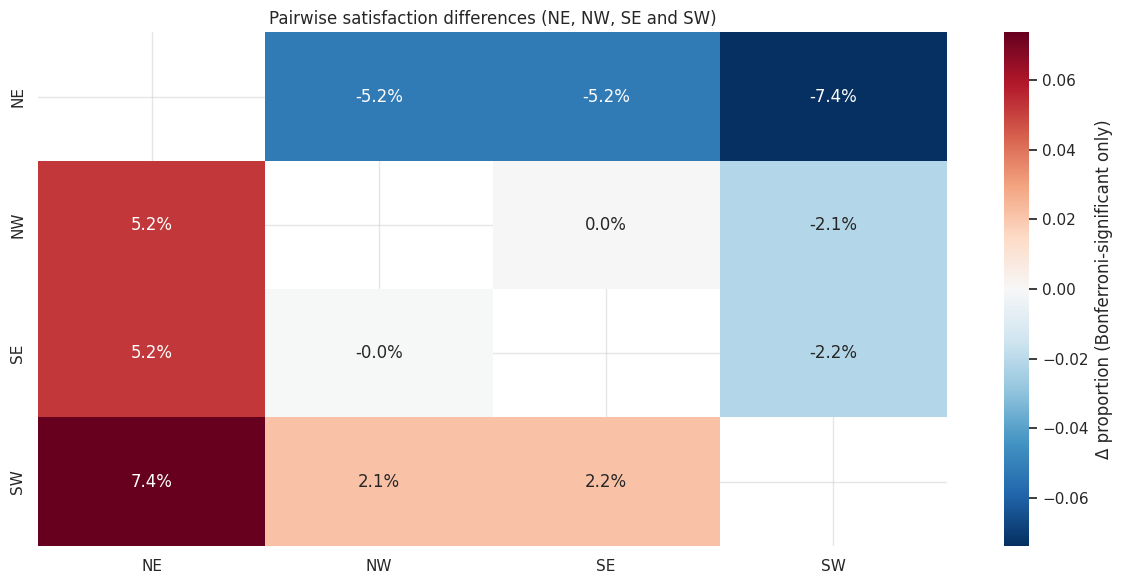

In [859]:
diff_mat = pd.DataFrame(np.nan, index=groups, columns=groups)
for _, r in res.iterrows():
    #if r['sig_bonf']:
        diff_mat.loc[r['group_1'], r['group_2']] = r['diff']
        diff_mat.loc[r['group_2'], r['group_1']] = -r['diff']

sns.heatmap(diff_mat, annot=True, fmt='.1%', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Δ proportion (Bonferroni-significant only)'})
plt.title('Pairwise satisfaction differences (NE, NW, SE and SW)')
plt.tight_layout()
plt.show()

In [851]:
# qol_df["Quadrant"] = pd.to_numeric(qol_df["Quadrant"], errors="coerce")
# qol_df["Quadrant_label"] = pd.Categorical(
#     qol_df["Quadrant"].map(quadrant_map),
#     categories=quadrant_map,
#     ordered=True)
#
# print(qol_df)

In [852]:
# print(len(survey_2018_2021))

In [853]:
survey_2020 = survey_2018_2021[survey_2018_2021["qwave"] == "Year-2020"]
survey_2020



,Mweight0,qwave,s4qt,market2,q39,q34,q37,q38,q30,q32x,...,q9_2_26,q9_2_27,q9_2_28,q9_2_29,q9_2_30,q9_2_31,q9_2_32,q9_2_33,q9_2_34,q9_2_35
2500,0.62,Year-2020,1,13,3,1,11,1,6,2,...,4,4,4,4,4,4,4,4,4,4
2501,0.63,Year-2020,2,14,7,1,5,4,5,2,...,2,3,2,2,3,3,2,1,3,1
2502,0.67,Year-2020,1,13,9,1,7,3,5,2,...,3,3,3,3,2,1,1,3,1,3
2503,0.95,Year-2020,3,2,8,1,6,3,4,1,...,1,3,3,3,3,3,3,3,3,3
2504,0.67,Year-2020,1,13,8,1,11,3,5,2,...,1,3,2,3,4,4,3,3,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,1.03,Year-2020,1,8,9,1,11,3,7,2,...,2,2,3,3,1,1,2,3,3,1
4996,0.72,Year-2020,4,10,3,1,11,2,6,2,...,4,4,4,4,4,4,4,4,4,4
4997,0.92,Year-2020,4,5,6,1,3,2,3,1,...,3,3,3,3,3,3,3,3,3,3
4998,0.54,Year-2020,3,2,1,1,8,2,5,2,...,4,4,4,4,4,4,4,4,4,4


In [854]:
survey_2020.describe()

,Mweight0,s4qt,market2,q39,q34,q37,q38,q30,q32x,q40,...,q9_2_26,q9_2_27,q9_2_28,q9_2_29,q9_2_30,q9_2_31,q9_2_32,q9_2_33,q9_2_34,q9_2_35
count,2500.000000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,...,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.00000,2500.00000,2500.000000
mean,1.000012,2.387600,7.676000,5.94760,1.265600,6.685600,2.354400,4.273200,1.744800,1.791600,...,3.116800,3.191200,3.201200,3.242400,3.283600,3.138000,3.112800,3.23440,3.29240,3.325200
std,0.488920,1.095558,4.039004,2.52939,0.645619,3.170926,0.745267,1.601121,0.451392,0.461578,...,1.032465,1.034926,1.033995,0.991179,0.950543,1.091894,1.096064,0.98785,0.91216,0.894296
min,0.480000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.00000,1.000000
25%,0.630000,1.000000,4.000000,4.00000,1.000000,4.000000,2.000000,3.000000,1.000000,2.000000,...,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,2.000000,3.00000,3.00000,3.000000
50%,0.920000,2.000000,8.000000,7.00000,1.000000,7.000000,3.000000,5.000000,2.000000,2.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.00000,4.00000,4.000000
75%,1.120000,3.000000,11.000000,8.00000,1.000000,9.000000,3.000000,6.000000,2.000000,2.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.00000,4.00000,4.000000
max,2.800000,4.000000,14.000000,9.00000,5.000000,12.000000,4.000000,7.000000,3.000000,3.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.00000,4.00000,4.000000


In [855]:
survey_2020.dtypes


Mweight0    float64
qwave           str
s4qt          int64
market2       int64
q39           int64
             ...   
q9_2_31       int64
q9_2_32       int64
q9_2_33       int64
q9_2_34       int64
q9_2_35       int64
Length: 139, dtype: object